# 2단계 — 모델 해석 (analysis_shap)

목표: A5-1 최종 모델을 다시 학습해 SHAP으로 "왜 그런 판정인가"를 설명하고, 1단계 페르소나와 연결한다.
먼저 `analysis_clustering` 노트북(또는 `python -m src.analysis_clustering`)을 실행해야 한다.

In [1]:
import json
import warnings
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore", category=UserWarning)
# shap이 불러오는 tqdm의 위젯 안내 경고. 출력에 로컬 경로가 남지 않게 숨긴다.
warnings.filterwarnings("ignore", message="IProgress not found")
pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)

from src import analysis_shap, explain
from src.analysis_clustering import load_result
from src.config import FEATURES, FIGURES_DIR, RF_PARAMS
from src.data import load_data

df = load_data()
clustering = load_result()
print("A5-1에서 가져온 설정:", RF_PARAMS)

A5-1에서 가져온 설정: {'n_estimators': 400, 'max_depth': 12, 'min_samples_leaf': 1, 'class_weight': 'balanced'}


## 1. 모델: A5-1 설정 재사용

A5-1 최종 모델(RF + class_weight)은 파생 변수(연령대, 부채액)를 썼다. A5-2는 임의 컬럼 추가를 금지하므로, **같은 하이퍼파라미터로 원본 6개 변수만 써서 다시 학습**한다.
분할(8:2 층화, seed 42)도 같아서 Test 2,000명이 A5-1과 같은 고객이다. 아래 실행이 학습·SHAP·그래프를 모두 만든다(SHAP 계산에 약 1분).

In [2]:
result = analysis_shap.run(df)
m = result["model"]
ref = m["a5_1"]
pd.DataFrame({
    "A5-2 (원본 6개)": {"CV F1": m["cv"]["f1_mean"], **{k: m["test"][k] for k in ("precision", "recall", "f1", "roc_auc", "pr_auc")}},
    "A5-1 (6개 + 파생)": {"CV F1": ref["cv"]["f1_mean"], **{k: ref["test"][k] for k in ("precision", "recall", "f1", "roc_auc", "pr_auc")}},
}).round(3)

[   0.0s] Train 8,000 / Test 2,000, 군집 6개 불러옴


[  15.1s] 모델 학습 완료: Test F1 0.644, 보류 임계값 0.178


[  71.7s] SHAP 계산 완료(Test 2,000명), 가법성 오차 2.1e-14


[  71.7s] Global·Local·Dependence 요약 완료


[  75.7s] 그래프 저장 완료


[  75.7s] 저장 완료: shap.json, test_explanations.json


,A5-2 (원본 6개),A5-1 (6개 + 파생)
CV F1,0.664,0.660
precision,0.543,0.546
recall,0.792,0.796
f1,0.644,0.647
roc_auc,0.940,0.940
pr_auc,0.640,0.634


파생 변수를 빼도 성능이 거의 같다. 부채액(소득×부채 비율)은 두 원본 변수로 트리가 직접 나눌 수 있고, 연령대는 노이즈 변수(나이)를 다시 쓴 것이기 때문이다.

## 2. SHAP의 기준값과 가법성

SHAP은 예측 = 기준값 + 변수별 기여의 합으로 나눈다. 기준값은 0.12(실제 연체율)가 아니라 약 0.50이다. `class_weight="balanced"`가 연체 표본에 약 7배 가중치를 주어 학습했기 때문에 모델 점수의 평균이 0.5 근처로 옮겨졌다.

In [3]:
print(f"기준값 E[f(X)] = {result['base_value']:.4f}")
print(f"가법성 최대 오차 = {result['additivity_error']:.1e}")
case = result["cases"]["reject_case"]
total = case["base_value"] + sum(c["shap"] for c in case["contributions"])
print(f"거절 사례: {case['base_value']:.4f} + {total - case['base_value']:+.4f} = {total:.4f} (모델 확률 {case['proba']:.4f})")

기준값 E[f(X)] = 0.4998
가법성 최대 오차 = 2.1e-14
거절 사례: 0.4998 + +0.3667 = 0.8665 (모델 확률 0.8665)


## 3. Global — Summary Plot

,mean_abs_shap,share,direction
feature,,,
annual_income,0.2434,0.4363,-0.9262
overdue_count_6m,0.1513,0.2712,0.8655
debt_ratio,0.1195,0.2142,0.9046
spending_score,0.0185,0.0332,0.1731
age,0.0157,0.0281,0.0788
credit_card_count,0.0095,0.0170,0.2304


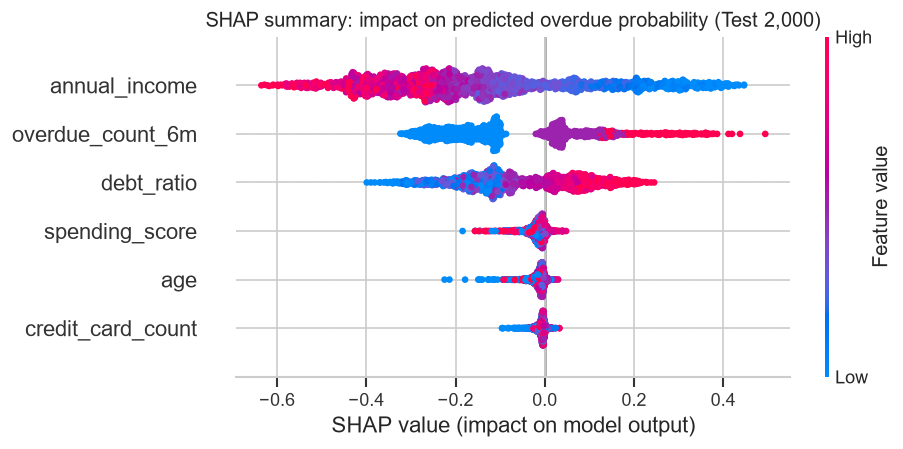

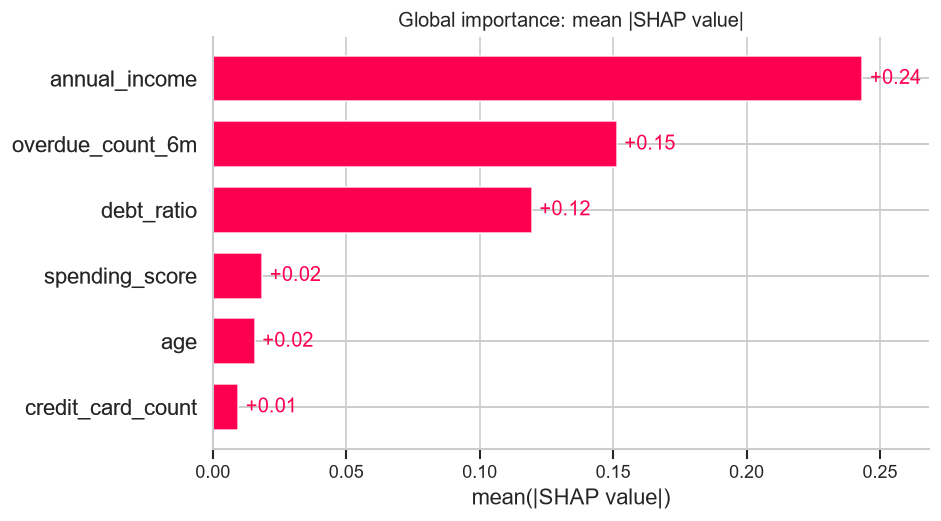

In [4]:
display(pd.DataFrame(result["global"]).set_index("feature"))
display(Image(FIGURES_DIR / "04_shap_summary.png"))
display(Image(FIGURES_DIR / "05_shap_importance_bar.png"))

- 상위 3개(소득, 연체 횟수, 부채 비율)가 영향의 92%를 차지한다. `data_gen.py`의 신용 점수 공식에 들어간 세 변수와 정확히 같다. 나이·소비 점수·카드 수는 공식에 없는 노이즈 변수이고 영향도 작다.
- 방향: 소득은 낮을수록, 연체 횟수와 부채 비율은 높을수록 연체 점수를 올린다(순위 상관 −0.93, +0.87, +0.90).
- 정답 공식을 아는 합성 데이터라서 설명이 맞는지 직접 검증할 수 있다. 실제 데이터에서는 이런 검증이 불가능하므로 SHAP은 "모델이 무엇을 보는가"이지 "세상의 인과"가 아니다.

## 4. Local — 승인·거절 사례

**reject_case** · C0 연체 반복형 · 확률 0.866 · 실제 연체 0 · 실제 신용 점수 288

,value,shap
feature,,
overdue_count_6m,2.00,0.3864
debt_ratio,0.43,-0.0797
annual_income,3873.00,0.0662
age,40.00,-0.0042
credit_card_count,5.00,-0.0034
spending_score,56.00,0.0014


- 평균적인 고객의 모델 점수는 50%이고, 이 고객은 87%입니다.
- 최근 6개월 연체 횟수(2회) 때문에 점수가 38.6%p 올라갔습니다.
- 부채 비율(0.43) 때문에 점수가 8.0%p 내려갔습니다.
- 연 소득(3,873만원) 때문에 점수가 6.6%p 올라갔습니다.


**approve_case** · C5 저부채 고소비 우량형 · 확률 0.000 · 실제 연체 0 · 실제 신용 점수 444

,value,shap
feature,,
overdue_count_6m,0.00,-0.1724
debt_ratio,0.17,-0.1685
annual_income,4699.00,-0.1415
age,48.00,-0.0100
credit_card_count,5.00,-0.0052
spending_score,82.00,-0.0018


- 평균적인 고객의 모델 점수는 50%이고, 이 고객은 0%입니다.
- 최근 6개월 연체 횟수(0회) 때문에 점수가 17.2%p 내려갔습니다.
- 부채 비율(0.17) 때문에 점수가 16.8%p 내려갔습니다.
- 연 소득(4,699만원) 때문에 점수가 14.1%p 내려갔습니다.


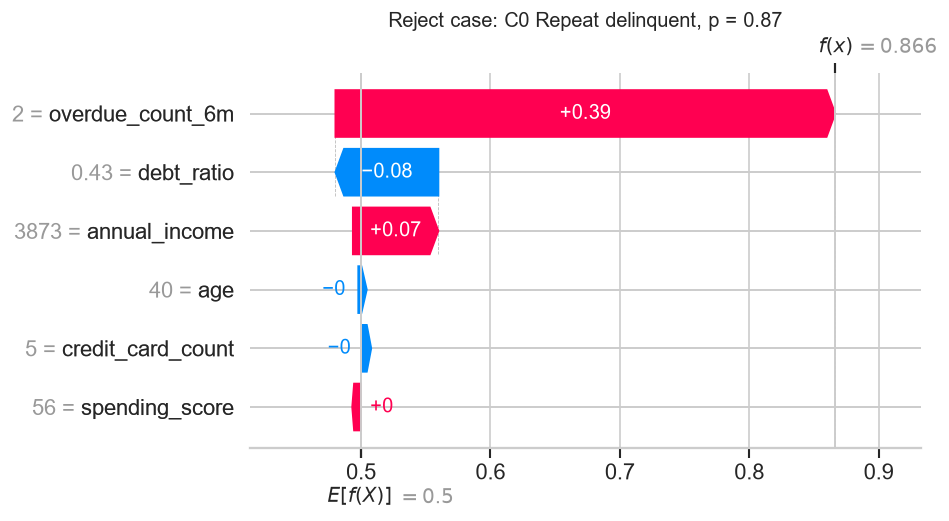

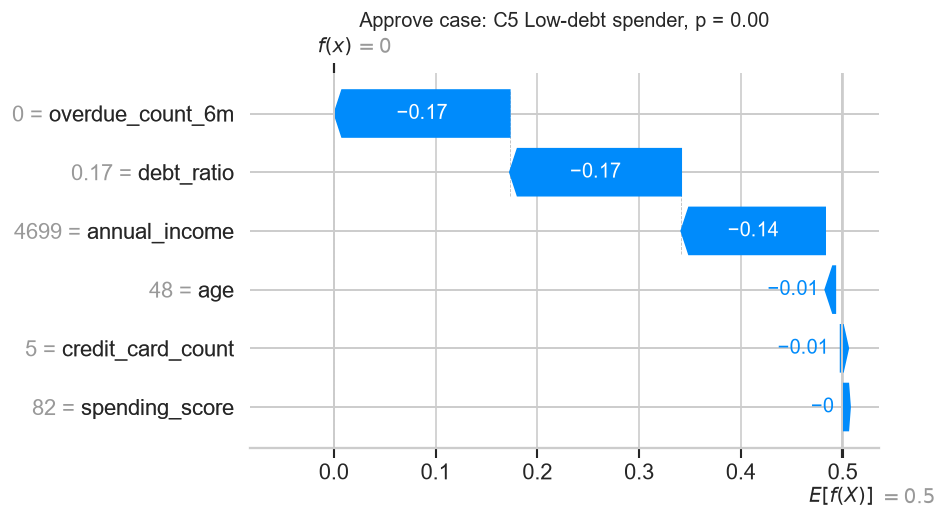

In [5]:
for key in ("reject_case", "approve_case"):
    c = result["cases"][key]
    display(Markdown(f"**{key}** · C{c['cluster']} {clustering['personas'][c['cluster']]['ko']} · 확률 {c['proba']:.3f} · "
                     f"실제 연체 {c['actual_overdue']} · 실제 신용 점수 {c['credit_score']:.0f}"))
    display(pd.DataFrame(c["contributions"]).set_index("feature"))
    for line in explain.narrate(c):
        print("-", line)
display(Image(FIGURES_DIR / "06_waterfall_reject.png"))
display(Image(FIGURES_DIR / "07_waterfall_approve.png"))

## 5. Dependence Plot

변수 선택: Summary 상위 2개(소득, 연체 횟수) + 비즈니스 변수 1개(부채 비율: 대출 규제와 상담에서 직접 다루는 변수).

연체 횟수별 소득 SHAP이 음수로 바뀌는 소득: {'0': 3425.0, '1': 3757.0, '2': 4000.0}
생성 공식상 점수 292점 경계 소득(부채 비율 0.5): {'1': 3067, '2': 4733}


group,overdue_count_6m=0,overdue_count_6m>=1
bin,,
"(1499.999, 2741.5]",0.281,0.289
"(2741.5, 3654.75]",0.041,0.117
"(3654.75, 4345.625]",-0.099,-0.043
"(4345.625, 4968.0]",-0.160,-0.145
"(4968.0, 5611.125]",-0.233,-0.289
"(5611.125, 6375.25]",-0.273,-0.372
"(6375.25, 7267.875]",-0.319,-0.460
"(7267.875, 11316.0]",-0.320,-0.475


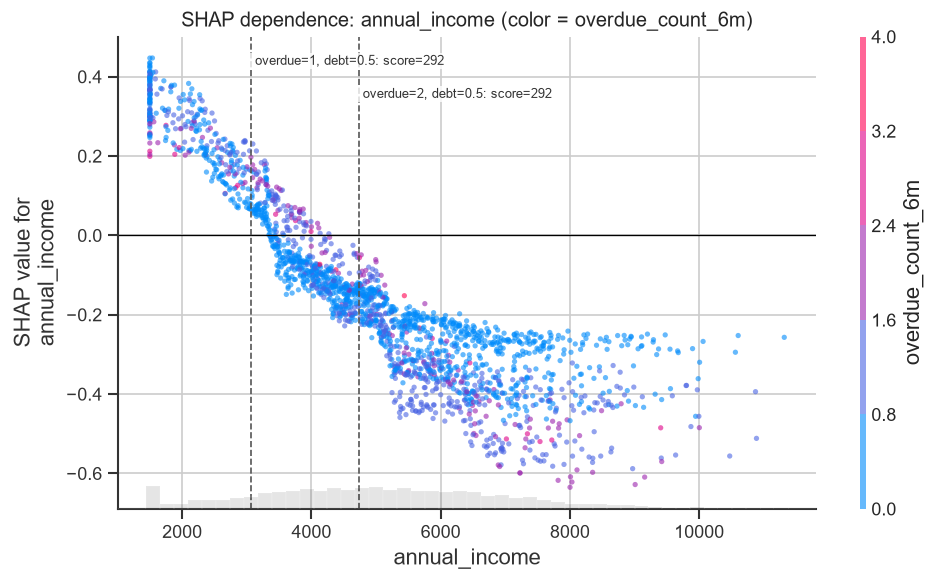

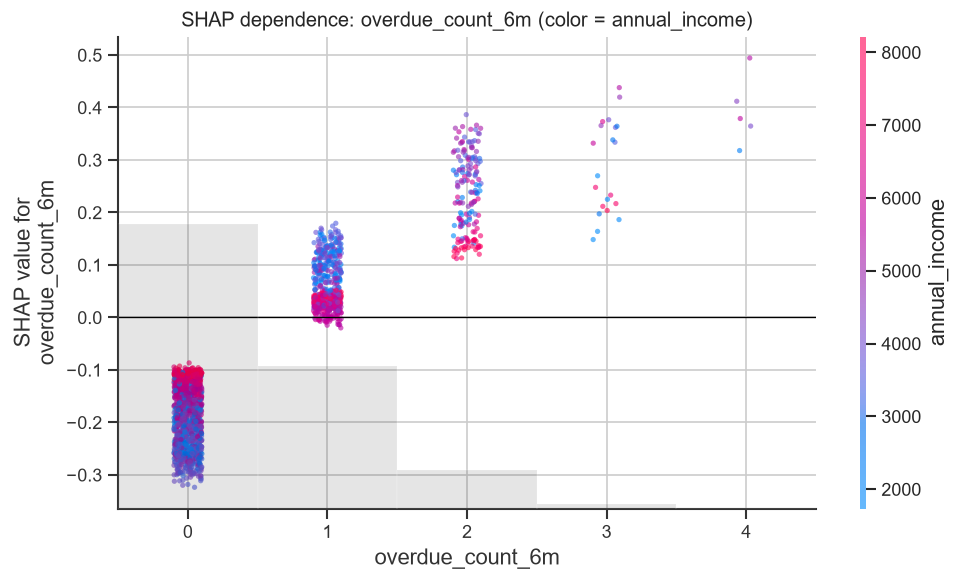

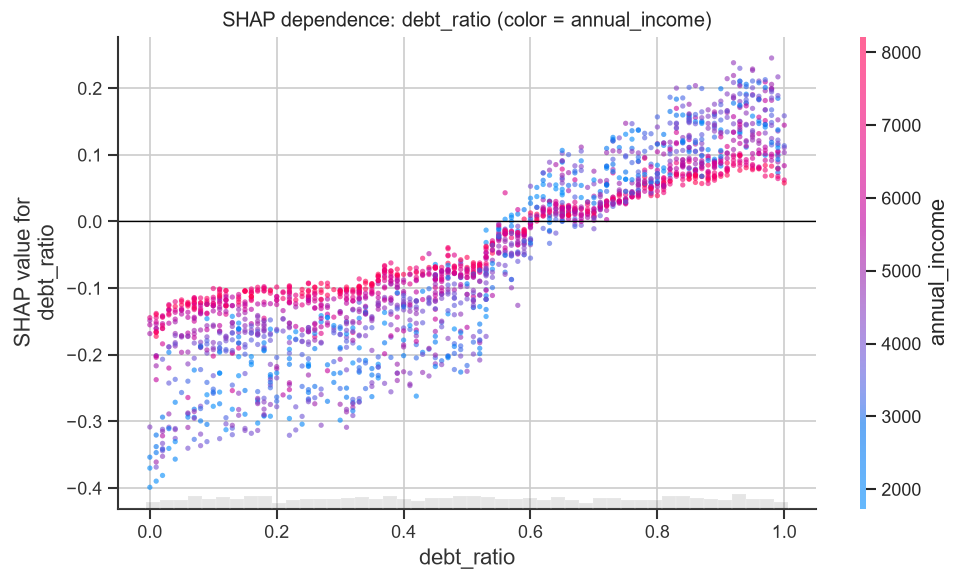

In [6]:
dep = result["dependence"]
print("연체 횟수별 소득 SHAP이 음수로 바뀌는 소득:", dep["income_crossing"])
print("생성 공식상 점수 292점 경계 소득(부채 비율 0.5):", {k: round(v) for k, v in dep["theoretical_income_boundary"].items()})
display(pd.DataFrame(dep["income_by_overdue"]).pivot(index="bin", columns="group", values="shap_mean").round(3))
for f in dep["features"]:
    n = 8 + dep["features"].index(f)
    display(Image(FIGURES_DIR / f"{n:02d}_dependence_{f}.png"))

## 6. 페르소나와 연결

,age,annual_income,spending_score,debt_ratio,credit_card_count,overdue_count_6m,mean_proba,n_test
C0 연체 반복형,-0.021,-0.154,-0.020,-0.060,-0.011,0.245,0.478,188
C1 고령·고부채 다카드형,-0.016,-0.128,-0.018,0.040,-0.007,-0.103,0.268,351
C2 청년·고부채 소비형,-0.016,-0.195,-0.013,0.043,-0.012,-0.100,0.205,358
C3 청년·다카드 절약형,-0.017,-0.167,-0.017,-0.071,-0.006,-0.097,0.125,386
C4 중장년·저소비 실속형,-0.011,-0.126,-0.017,-0.105,-0.010,-0.111,0.118,339
C5 저부채 고소비 우량형,-0.011,-0.134,-0.015,-0.163,-0.006,-0.107,0.064,378


,approve,review,reject
C0 연체 반복형,59,31,98
C1 고령·고부채 다카드형,202,58,91
C2 청년·고부채 소비형,241,50,67
C3 청년·다카드 절약형,311,33,42
C4 중장년·저소비 실속형,280,22,37
C5 저부채 고소비 우량형,338,25,15


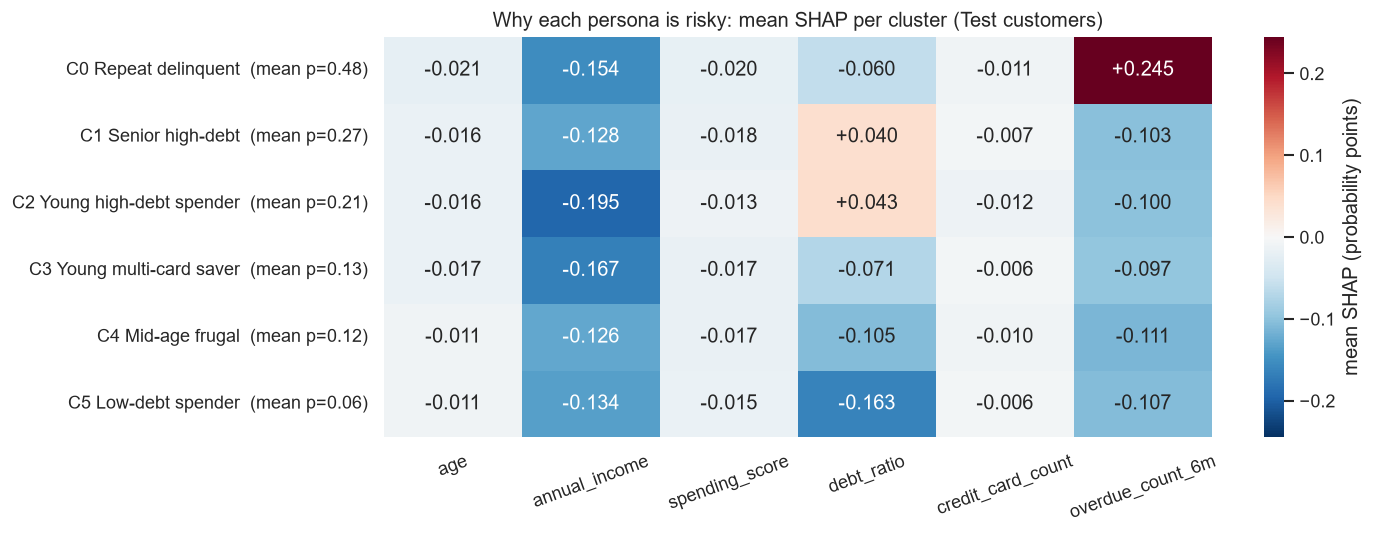

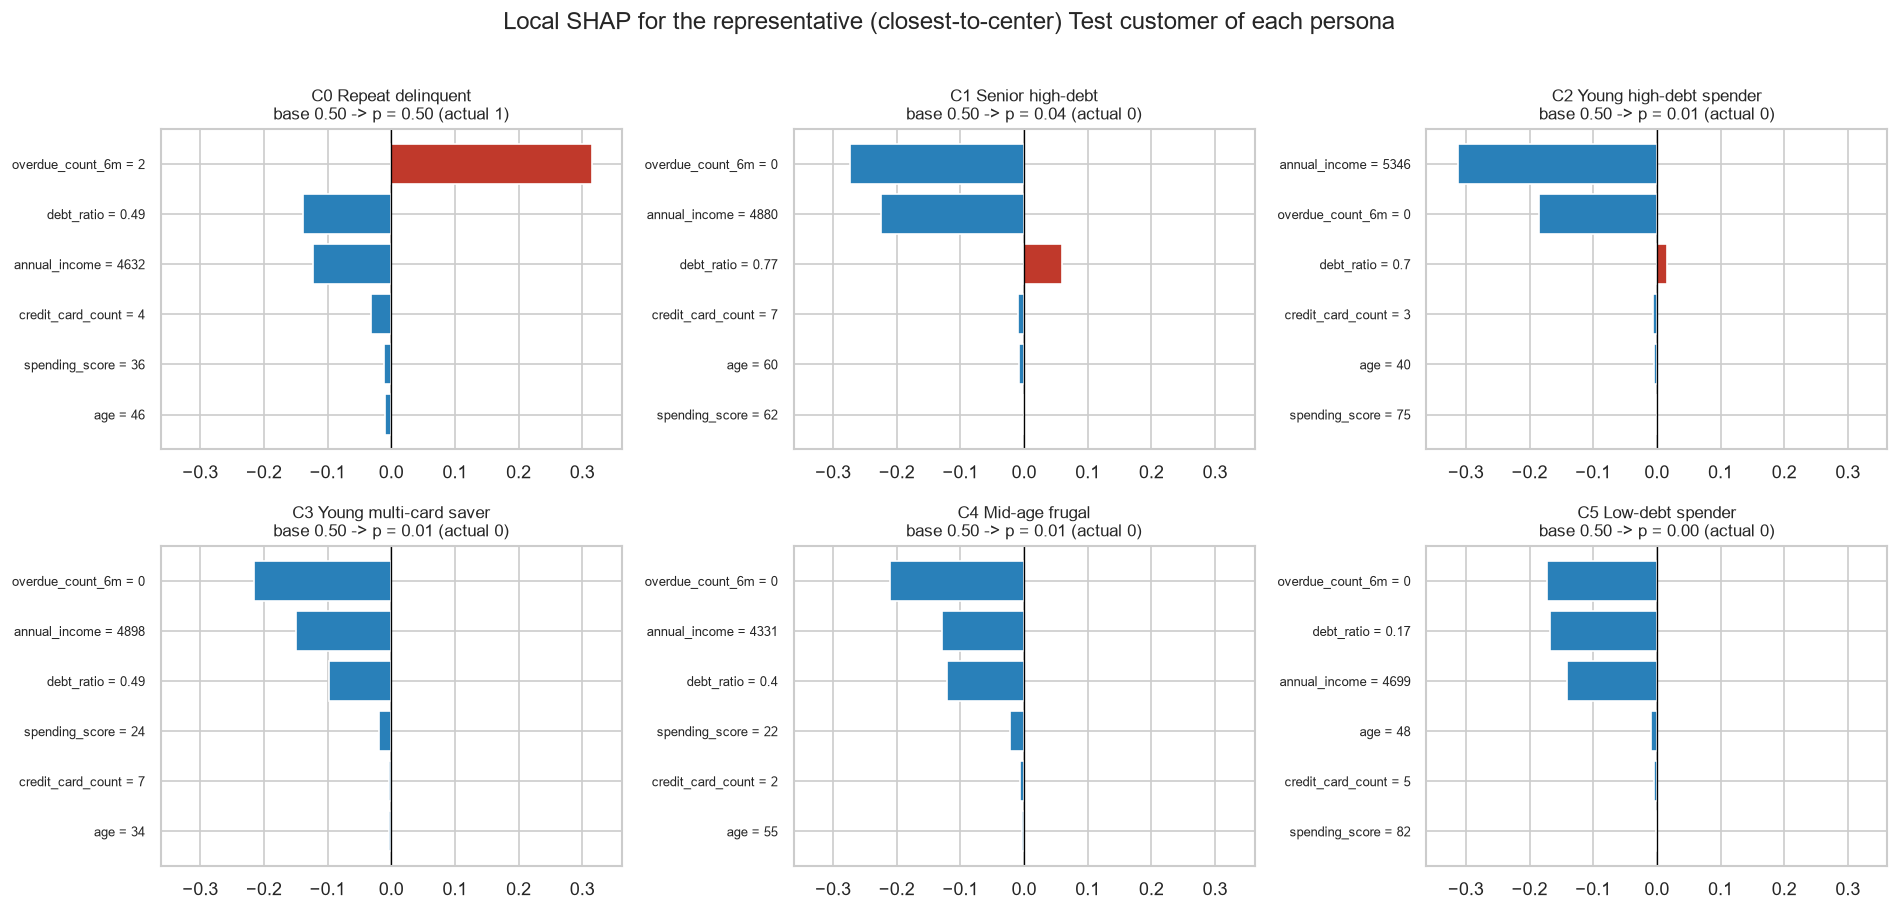

In [7]:
names = [f"C{p['cluster']} {p['ko']}" for p in clustering["personas"]]
cs = pd.DataFrame([r["mean_shap"] | {"mean_proba": r["mean_proba"], "n_test": r["n_test"]} for r in result["cluster_shap"]], index=names)
display(cs.round(3))
display(pd.DataFrame(result["cluster_band_crosstab"]).T.set_axis(names))
display(Image(FIGURES_DIR / "11_cluster_shap.png"))
display(Image(FIGURES_DIR / "12_persona_cases.png"))

- C0(연체 반복형)는 연체 횟수 SHAP 평균이 +0.25로 위험을 끌어올린다. C5(저부채 고소비 우량형)는 부채 비율 SHAP 평균이 −0.16으로 위험을 끌어내린다.
- 소득은 어느 군집도 구별하지 않는다(모든 군집에서 z가 ±0.11 이내). 그런데 모델이 가장 중요하게 보는 변수는 소득이다. 군집화는 모든 변수를 똑같은 거리로 다루고, 분류 모델은 정답과 관련된 변수만 본다. 그래서 같은 페르소나 안에도 위험이 크게 다른 고객이 섞인다. 페르소나는 마케팅 단위로 쓰고, 심사는 개별 점수와 SHAP 근거로 해야 한다.